In [ ]:
# importation des bib
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from langchain_core.documents import Document

### chargement etNettoyage des textes

In [22]:
doc=[]
for path in Path("data/raw").rglob("*.txt"):
    with open(path, "r", encoding="utf-8") as f:
        text = f.read()
        print(f"File: {path}, Length: {len(text)} characters")
        doc.append({
            "source_path" :path.name,
            "text" : text }
        )
df =pd.DataFrame(doc)
df.head()


File: data/raw/ml.txt, Length: 2721 characters
File: data/raw/langchain.txt, Length: 3072 characters
File: data/raw/ai.txt, Length: 2515 characters
File: data/raw/python.txt, Length: 2589 characters


,source_path,text
0,ml.txt,Machine Learning (ML)\n\nMachine Learning is a...
1,langchain.txt,LangChain Framework\n\nLangChain is an open so...
2,ai.txt,Artificial Intelligence (AI)\n\nArtificial Int...
3,python.txt,Python Programming Language\n\nPython is a hig...


In [24]:
print("Nombre de documents :", len(df))

df["characters"] = df["text"].apply(len)
df["words"] = df["text"].apply(lambda x: len(x.split()))

df[["source_path", "characters", "words"]]

Nombre de documents : 4


,source_path,characters,words
0,ml.txt,2721,402
1,langchain.txt,3072,444
2,ai.txt,2515,380
3,python.txt,2589,379


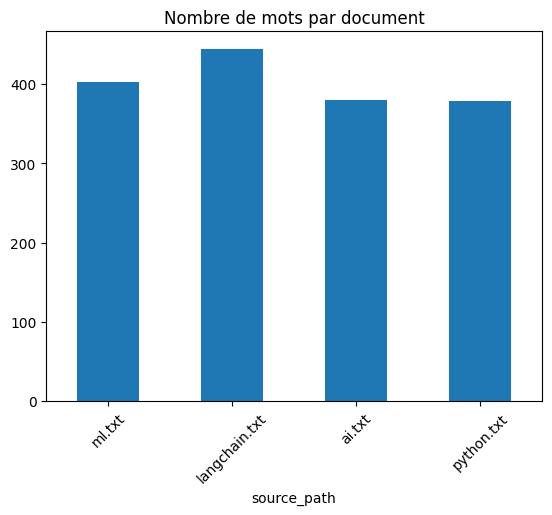

In [26]:
df.plot(
    x="source_path",
    y="words",
    kind="bar",
    legend=False,
    title="Nombre de mots par document"
)
plt.xticks(rotation=45)
plt.show()

In [27]:
def clean_text(text):
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{2,}', '\n', text)
    text = text.strip()
    return text

In [28]:
df["cleaned_text"] = df["text"].apply(clean_text)

In [29]:
df["cleaned_text"]

0    Machine Learning (ML)\nMachine Learning is a s...
1    LangChain Framework\nLangChain is an open sour...
2    Artificial Intelligence (AI)\nArtificial Intel...
3    Python Programming Language\nPython is a high ...
Name: cleaned_text, dtype: object

### Découpage en paragraphes

In [30]:
df["cleaned_text"] = df["cleaned_text"].str.split("\n")

In [31]:
for i, paragraphs in enumerate(df["cleaned_text"]):
    print(f"\nDocument {i+1} : {len(paragraphs)} paragraphes")
    for j, paragraph in enumerate(paragraphs):
        print(f"Paragraphe {j+1}: {paragraph[:150]}")


Document 1 : 16 paragraphes
Paragraphe 1: Machine Learning (ML)
Paragraphe 2: Machine Learning is a subset of Artificial Intelligence that gives computers the ability to learn from data and improve their performance over time wi
Paragraphe 3: How Machine Learning Works
Paragraphe 4: A machine learning system is trained using a dataset. During training, the algorithm looks for patterns and relationships in the data. Once trained, t
Paragraphe 5: Types of Machine Learning
Paragraphe 6: Supervised learning uses labeled data, where each training example has an input and a known correct output. The model learns to map inputs to outputs.
Paragraphe 7: Unsupervised learning uses data without labels. The algorithm tries to find hidden patterns or groupings in the data on its own. Clustering and dimens
Paragraphe 8: Reinforcement learning involves an agent that learns by interacting with an environment. The agent receives rewards or penalties based on its actions 
Paragraphe 9: Common Machine 

In [39]:
df_text = pd.DataFrame(columns=["text"])
m = 0
for i in df["cleaned_text"]:
    for h,j in enumerate(i):
        df_text.loc[m, "text"] = j
        m = m+1
           


In [40]:
len(df_text["text"])

59

In [41]:
df_text["text"]

0                                 Machine Learning (ML)
1     Machine Learning is a subset of Artificial Int...
2                            How Machine Learning Works
3     A machine learning system is trained using a d...
4                             Types of Machine Learning
5     Supervised learning uses labeled data, where e...
6     Unsupervised learning uses data without labels...
7     Reinforcement learning involves an agent that ...
8                    Common Machine Learning Algorithms
9     Linear regression predicts a continuous value ...
10                        The Machine Learning Workflow
11    A typical machine learning project involves se...
12                         Overfitting and Underfitting
13    Overfitting occurs when a model learns the tra...
14                     Applications of Machine Learning
15    Machine learning powers recommendation systems...
16                                  LangChain Framework
17    LangChain is an open source framework desi

### Génération des embeddings

In [ ]:
documents = [
    Document(
        page_content=row["text"],
        metadata={"paragraph_id": str(idx)}
    )
    for idx, row in df_text.iterrows()
    if isinstance(row["text"], str) and row["text"].strip()
]

CUDA disponible : False
